На этом семинаре вновь будем работать с MovieLens-1M:

1. Построим рекомендации похожих айтемов. Сначала представим фильмы с помощью жанров и названий. а затем посмотрим, какие фильмы часто нравятся одним и тем же пользователям, и на основе этого сделаем I2I-рекомендации.
2. Обучим CoLES: получим эмбеддинги пользователей по последовательностям оценок и проверим их на downstream-задаче классификации.

## 0. Установка и импорты

In [22]:
%pip install -q polars numpy scipy scikit-learn matplotlib requests tqdm

In [23]:
import os
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler, normalize
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
)
DATA_DIR = Path("data/14_seminar")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print(DEVICE)

cuda


## 1. Данные

[MovieLens-1M](https://grouplens.org/datasets/movielens/1m/) — классический
бенчмарк-датасет: явные рейтинги от 1 до 5, у каждого взаимодействия есть
таймстемп. Также есть метаданые по юзерам и айтемам.

In [24]:
def download(url: str, path: Path, chunk_size: int = 1 << 16) -> Path:
    """Скачивает файл по адресу url, если он ещё не сохранён локально."""
    path = Path(path)
    if path.exists():
        return path

    path.parent.mkdir(parents=True, exist_ok=True)
    response = requests.get(url, stream=True, headers={"User-Agent": "Mozilla/5.0"})
    response.raise_for_status()
    total = int(response.headers.get("content-length", 0))

    tmp_path = path.with_suffix(path.suffix + ".part")
    with open(tmp_path, "wb") as file, tqdm(total=total, unit="B", unit_scale=True) as pbar:
        for chunk in response.iter_content(chunk_size=chunk_size):
            if chunk:
                file.write(chunk)
                pbar.update(len(chunk))

    tmp_path.rename(path)
    return path


def download_and_unzip(url: str, extract_root: Path, name: str) -> Path:
    """Скачивает и распаковывает архив, повторно используя локальную копию."""
    extract_root = Path(extract_root)
    marker = extract_root / f".{name}.ready"

    if not marker.exists():
        extract_root.mkdir(parents=True, exist_ok=True)
        archive = download(url, extract_root / f"{name}.zip")

        with zipfile.ZipFile(archive) as zip_file:
            zip_file.extractall(extract_root)

        marker.touch()

    return extract_root / name


def convert_movielens_to_tsv(source: Path, encoding: str = "utf-8") -> Path:
    """Однократно меняет разделитель :: на табуляцию и переводит текст в UTF-8."""
    target = source.with_suffix(".tsv")
    if not target.exists():
        text = source.read_bytes().decode(encoding)
        target.write_text(text.replace("::", "\t"), encoding="utf-8")

    return target

In [25]:
ML1M_DIR = download_and_unzip(
    "https://files.grouplens.org/datasets/movielens/ml-1m.zip",
    DATA_DIR,
    "ml-1m",
)

ml_ratings = pl.read_csv(
    convert_movielens_to_tsv(ML1M_DIR / "ratings.dat"),
    separator="\t",
    has_header=False,
    quote_char=None,
    new_columns=["user_id", "movie_id", "rating", "timestamp"],
)

ml_movies = pl.read_csv(
    convert_movielens_to_tsv(ML1M_DIR / "movies.dat", encoding="latin-1"),
    separator="\t",
    has_header=False,
    quote_char=None,
    new_columns=["movie_id", "title", "genres"],
)

ml_users = pl.read_csv(
    convert_movielens_to_tsv(ML1M_DIR / "users.dat"),
    separator="\t",
    has_header=False,
    quote_char=None,
    new_columns=["user_id", "gender", "age_group", "occupation", "zip_code"],
    schema_overrides={"zip_code": pl.String},
)

print(
    f"MovieLens-1M: {ml_ratings.height} оценок, "
    f"{ml_users.height} пользователей, {ml_movies.height} фильмов"
)
display(ml_movies.head(3), ml_ratings.head(3), ml_users.head(3))

MovieLens-1M: 1000209 оценок, 6040 пользователей, 3883 фильмов


movie_id,title,genres
i64,str,str
1,"""Toy Story (1995)""","""Animation|Children's|Comedy"""
2,"""Jumanji (1995)""","""Adventure|Children's|Fantasy"""
3,"""Grumpier Old Men (1995)""","""Comedy|Romance"""


user_id,movie_id,rating,timestamp
i64,i64,i64,i64
1,1193,5,978300760
1,661,3,978302109
1,914,3,978301968


user_id,gender,age_group,occupation,zip_code
i64,str,i64,i64,str
1,"""F""",1,10,"""48067"""
2,"""M""",56,16,"""70072"""
3,"""M""",25,15,"""55117"""


### Единая индексация

Исходные идентификаторы MovieLens не образуют непрерывный диапазон. Чтобы обращаться к строкам матриц непосредственно по `movie_id` и `user_id`, один раз перенумеруем фильмы и пользователей от нуля. Старые значения сохраним в столбцах `original_movie_id` и `original_user_id`.

Затем присоединим новые идентификаторы к таблице оценок. В дальнейшем дополнительных словарей преобразования индексов не понадобится. Жанры представим списками строк.

In [26]:
ml_movies = (
    ml_movies
    .rename({"movie_id": "original_movie_id"})
    .sort("original_movie_id")
    .with_row_index("movie_id")
    .with_columns(
        pl.col("genres").str.split("|"),
        pl.col("title").str.extract(r"\((\d{4})\)\s*$", 1).cast(pl.Int16).alias("year"),
    )
)

ml_users = (
    ml_users
    .rename({"user_id": "original_user_id"})
    .sort("original_user_id")
    .with_row_index("user_id")
)

ml_ratings = (
    ml_ratings
    .rename({"user_id": "original_user_id", "movie_id": "original_movie_id"})
    .join(ml_users.select("original_user_id", "user_id"), on="original_user_id")
    .join(ml_movies.select("original_movie_id", "movie_id"), on="original_movie_id")
    .select("user_id", "movie_id", "rating", "timestamp")
    .sort("user_id", "timestamp", "movie_id")
)

assert ml_movies["movie_id"].to_list() == list(range(ml_movies.height))
assert ml_users["user_id"].to_list() == list(range(ml_users.height))
assert ml_ratings["movie_id"].max() < ml_movies.height
assert ml_ratings["user_id"].max() < ml_users.height

N_USERS = ml_users.height
N_MOVIES = ml_movies.height

display(ml_movies.head(3), ml_ratings.head(3))

movie_id,original_movie_id,title,genres,year
u32,i64,str,list[str],i16
0,1,"""Toy Story (1995)""","[""Animation"", ""Children's"", ""Comedy""]",1995
1,2,"""Jumanji (1995)""","[""Adventure"", ""Children's"", ""Fantasy""]",1995
2,3,"""Grumpier Old Men (1995)""","[""Comedy"", ""Romance""]",1995


user_id,movie_id,rating,timestamp
u32,u32,i64,i64
0,3117,4,978300019
0,1009,5,978300055
0,1250,5,978300055


Посмотрим на распределение оценок и популярность фильмов: популярные объекты способны доминировать в коллаборативных рекомендациях.

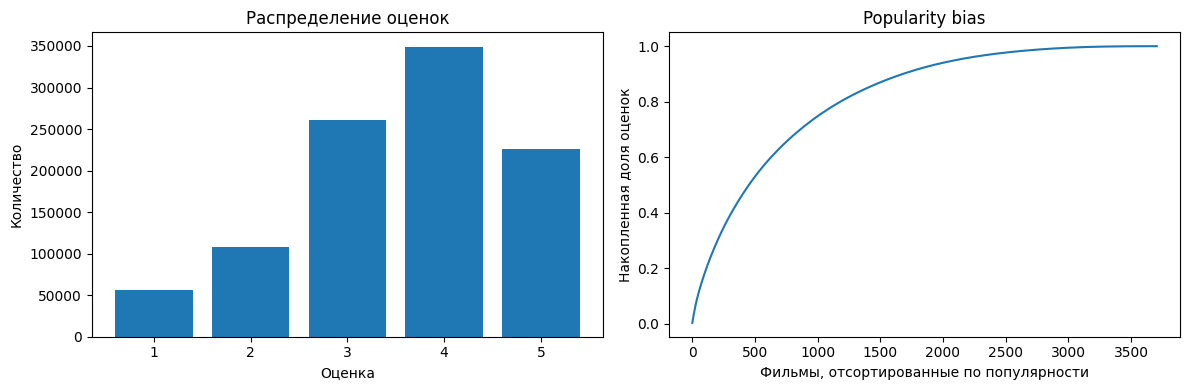

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rating_counts = ml_ratings["rating"].value_counts().sort("rating")
axes[0].bar(rating_counts["rating"].to_numpy(), rating_counts["count"].to_numpy())
axes[0].set(title="Распределение оценок", xlabel="Оценка", ylabel="Количество")

popularity = ml_ratings["movie_id"].value_counts(sort=True)["count"].to_numpy()
axes[1].plot(np.arange(1, len(popularity) + 1), np.cumsum(popularity) / popularity.sum())
axes[1].set(
    title="Popularity bias",
    xlabel="Фильмы, отсортированные по популярности", ylabel="Накопленная доля оценок",
)

plt.tight_layout()
plt.show()

In [31]:
topn = 10
ml_top_popular = (
    ml_ratings.group_by("movie_id").agg(pl.len().alias("n_ratings"))
    .sort("n_ratings", descending=True).head(topn)
    .join(ml_movies, on="movie_id", how="left")
)

assert ml_top_popular.height == topn
ml_top_popular.select("movie_id", "title", "n_ratings")

movie_id,title,n_ratings
u32,str,u32
2789,"""American Beauty (1999)""",3428
257,"""Star Wars: Episode IV - A New …",2991
1178,"""Star Wars: Episode V - The Emp…",2990
1192,"""Star Wars: Episode VI - Return…",2883
476,"""Jurassic Park (1993)""",2672
1959,"""Saving Private Ryan (1998)""",2653
585,"""Terminator 2: Judgment Day (19…",2649
2502,"""Matrix, The (1999)""",2590
1250,"""Back to the Future (1985)""",2583


## I. I2I

### 1. Content-based

Начнём с контентного сходства: фильмы считаются похожими, если у них похожи метаданные. Для каждого фильма построим вектор из двух частей:

1. Multi-hot представление жанров: единица обозначает наличие соответствующего жанра.
2. TF-IDF представление названия без года выпуска.

Объединим и нормируем признаки. Сходство двух фильмов измерим с помощью метрики косинусного сходства:

$$
\operatorname{sim}_{\mathrm{content}}(i,j)
=\frac{\langle x_i,x_j\rangle}{\|x_i\|\,\|x_j\|}.
$$

In [32]:
mlb = MultiLabelBinarizer()
G = mlb.fit_transform(ml_movies["genres"].to_list()).astype(np.float32)
N_GENRES = G.shape[1]

print("Жанры:", ", ".join(mlb.classes_))

title_text = ml_movies["title"].str.replace(r"\s*\(\d{4}\)\s*$", "").to_list()
X_genre = normalize(sparse.csr_matrix(G), norm="l2")
X_title = TfidfVectorizer(
    stop_words="english", ngram_range=(1, 2), sublinear_tf=True
).fit_transform(title_text)

GENRE_WEIGHT = 0.9
X_content = sparse.hstack(
    [np.sqrt(GENRE_WEIGHT) * X_genre, np.sqrt(1 - GENRE_WEIGHT) * X_title],
    format="csr",
).astype(np.float32)
X_content = normalize(X_content, norm="l2")

Жанры: Action, Adventure, Animation, Children's, Comedy, Crime, Documentary, Drama, Fantasy, Film-Noir, Horror, Musical, Mystery, Romance, Sci-Fi, Thriller, War, Western


In [33]:
def best_indices(scores, k=10):
    """Возвращает индексы k объектов с наибольшими положительными оценками сходства."""
    scores = np.asarray(scores)
    eligible = np.flatnonzero(np.isfinite(scores) & (scores > 0))
    if len(eligible) == 0:
        return np.array([], dtype=np.int64)

    k = min(k, len(eligible))
    top = eligible[np.argpartition(scores[eligible], -k)[-k:]]
    return top[np.argsort(-scores[top], kind="stable")]


def find_movie(title):
    """Возвращает movie_id по названию."""
    found = ml_movies.filter(pl.col("title") == title)
    if found.is_empty():
        raise ValueError(f"Фильм не найден: {title}")

    return int(found["movie_id"][0])


def show_recommendations(scores, k=10):
    """Формирует таблицу рекомендаций по массиву оценок сходства."""
    indices = best_indices(scores, k)
    recommendations = pl.DataFrame({
        "movie_id": indices.astype(np.uint32),
        "score": scores[indices].astype(np.float32),
    })

    return (
        recommendations
        .join(ml_movies.select("movie_id", "title", "genres"), on="movie_id")
        .select("movie_id", "title", "genres", "score")
        .sort("score", descending=True)
    )


def content_scores(movie_id):
    """Косинусная близость к фильму movie_id."""
    scores = (X_content @ X_content[movie_id].T).toarray().ravel().astype(np.float32)
    scores[movie_id] = -np.inf
    return scores

In [34]:
for title in ["Toy Story (1995)", "Matrix, The (1999)"]:
    movie_id = find_movie(title)
    print(f"\nПохожие фильмы для {title}:")
    display(show_recommendations(content_scores(movie_id)))


Похожие фильмы для Toy Story (1995):


movie_id,title,genres,score
u32,str,list[str],f32
3045,"""Toy Story 2 (1999)""","[""Animation"", ""Children's"", ""Comedy""]",1.0
1050,"""Aladdin and the King of Thieve…","[""Animation"", ""Children's"", ""Comedy""]",0.9
2072,"""American Tail, An (1986)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
2073,"""American Tail: Fievel Goes Wes…","[""Animation"", ""Children's"", ""Comedy""]",0.9
2285,"""Rugrats Movie, The (1998)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
2286,"""Bug's Life, A (1998)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
3542,"""Saludos Amigos (1943)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
3682,"""Chicken Run (2000)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
3685,"""Adventures of Rocky and Bullwi…","[""Animation"", ""Children's"", ""Comedy""]",0.9



Похожие фильмы для Matrix, The (1999):


movie_id,title,genres,score
u32,str,list[str],f32
683,"""Solo (1996)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9
738,"""Arrival, The (1996)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9
1024,"""Lawnmower Man, The (1992)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9
1220,"""Terminator, The (1984)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9
1533,"""Face/Off (1997)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9
1763,"""Lost in Space (1998)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9
2531,"""eXistenZ (1999)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9
2653,"""Deep Blue Sea (1999)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9
3458,"""Predator (1987)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.9


**Вопросы**

1. Почему контентная модель чаще всего предлагает фильмы тех же жанров?
2. Насколько адекватной вам кажется идея конкатенции multi-hot вектора и TF-IDF представления?

### 2. Collaborative: PPMI

Попробуем определять сходство по поведению аудитории. Два фильма могут быть связаны, если их высоко оценивали одни и те же пользователи, даже когда их жанры различаются.

Примем за положительное взаимодействие оценку 4 или 5. Пусть $R$ — бинарная матрица «пользователи × фильмы». Тогда число совместных взаимодействий содержит матрица

$$C=R^\top R.$$

Простая совместная встречаемость зависит от популярности. Используем Pointwise Mutual Information:

$$
\operatorname{PMI}(i,j)=\log\frac{N\,c_{ij}}{c_i c_j},
\qquad \operatorname{PPMI}(i,j)=\max\{0,\operatorname{PMI}(i,j)\}.
$$

Здесь $c_i$ — число пользователей, положительно оценивших фильм $i$, а $N$ — число пользователей.

PMI может завышать связь редких пар. Поэтому ограничим минимальную поддержку и слегка сгладим оценку. В этой части исследуем похожесть фильмов по всем доступным оценкам, а не строим временной эксперимент с прогнозом будущих взаимодействий.

In [35]:
liked = ml_ratings.filter(pl.col("rating") >= 4).unique(["user_id", "movie_id"])
R = sparse.csr_matrix(
    (
        np.ones(liked.height, dtype=np.float32),
        (liked["user_id"].to_numpy(), liked["movie_id"].to_numpy()),
    ),
    shape=(N_USERS, N_MOVIES),
    dtype=np.float32,
)

item_counts = np.asarray(R.sum(axis=0)).ravel()
co = (R.T @ R).tocoo()

MIN_SUPPORT = 25
MIN_CO = 5
SHRINK = 25.0
valid = (
    (co.row != co.col)
    & (co.data >= MIN_CO)
    & (item_counts[co.row] >= MIN_SUPPORT)
    & (item_counts[co.col] >= MIN_SUPPORT)
)

row, col, intersections = co.row[valid], co.col[valid], co.data[valid]
pmi = np.log(intersections * N_USERS / (item_counts[row] * item_counts[col]))
ppmi = np.maximum(pmi, 0)
cosine = intersections / np.sqrt(item_counts[row] * item_counts[col])
weights = (0.65 * ppmi / (1 + ppmi) + 0.35 * cosine) * intersections / (intersections + SHRINK)

positive = weights > 0
S_collab = sparse.coo_matrix(
    (weights[positive].astype(np.float32), (row[positive], col[positive])),
    shape=(N_MOVIES, N_MOVIES),
).tocsr()
S_collab.setdiag(0)
S_collab.eliminate_zeros()


def collab_scores(movie_id):
    """Коллаборативное сходство с фильмом movie_id."""
    scores = S_collab.getrow(movie_id).toarray().ravel()
    scores[movie_id] = -np.inf
    return scores

In [36]:
for title in ["Toy Story (1995)", "Matrix, The (1999)"]:
    movie_id = find_movie(title)
    print(f"\nКоллаборативные соседи для {title}:")
    display(show_recommendations(collab_scores(movie_id)))


Коллаборативные соседи для Toy Story (1995):


movie_id,title,genres,score
u32,str,list[str],f32
3045,"""Toy Story 2 (1999)""","[""Animation"", ""Children's"", ""Comedy""]",0.499881
584,"""Aladdin (1992)""","[""Animation"", ""Children's"", … ""Musical""]",0.46714
360,"""Lion King, The (1994)""","[""Animation"", ""Children's"", ""Musical""]",0.447949
591,"""Beauty and the Beast (1991)""","[""Animation"", ""Children's"", ""Musical""]",0.445173
2286,"""Bug's Life, A (1998)""","[""Animation"", ""Children's"", ""Comedy""]",0.439886
33,"""Babe (1995)""","[""Children's"", ""Comedy"", ""Drama""]",0.41502
3327,"""Muppet Movie, The (1979)""","[""Children's"", ""Comedy""]",0.413864
3184,"""Wayne's World (1992)""","[""Comedy""]",0.413563
1245,"""Groundhog Day (1993)""","[""Comedy"", ""Romance""]",0.413562



Коллаборативные соседи для Matrix, The (1999):


movie_id,title,genres,score
u32,str,list[str],f32
585,"""Terminator 2: Judgment Day (19…","[""Action"", ""Sci-Fi"", ""Thriller""]",0.471713
2847,"""Total Recall (1990)""","[""Action"", ""Adventure"", … ""Thriller""]",0.462156
1491,"""Fifth Element, The (1997)""","[""Action"", ""Sci-Fi""]",0.460764
1220,"""Terminator, The (1984)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.445778
1182,"""Aliens (1986)""","[""Action"", ""Sci-Fi"", … ""War""]",0.443148
31,"""Twelve Monkeys (1995)""","[""Drama"", ""Sci-Fi""]",0.440487
1533,"""Face/Off (1997)""","[""Action"", ""Sci-Fi"", ""Thriller""]",0.438356
453,"""Fugitive, The (1993)""","[""Action"", ""Thriller""]",0.436464
770,"""Independence Day (ID4) (1996)""","[""Action"", ""Sci-Fi"", ""War""]",0.434864


**Вопрос**

Чем опасны пары, встретившиеся вместе всего несколько раз?

### 3. Hybrid

Контентная и коллаборативная модели измеряют разные виды сходства. Объединим оценки взвешенной суммой:

$$
\operatorname{sim}_{\mathrm{hybrid}}(i,j)
=\alpha\operatorname{sim}_{\mathrm{content}}(i,j)
+(1-\alpha)\operatorname{sim}_{\mathrm{collab}}(i,j).
$$

В обоих случаях положительные значения лежат в сопоставимом диапазоне. Параметр $\alpha$ позволяет менять вклад каждого источника информации.

In [37]:
def hybrid_scores(movie_id, alpha=0.5):
    assert 0 <= alpha <= 1

    content = content_scores(movie_id)
    collaborative = collab_scores(movie_id)
    content[movie_id] = 0
    collaborative[movie_id] = 0

    scores = alpha * content + (1 - alpha) * collaborative
    scores[movie_id] = -np.inf
    return scores


movie_id = find_movie("Toy Story (1995)")

for alpha in [0.0, 0.5, 1.0]:
    print(f"\nДоля контентного сигнала: {alpha:.1f}")
    display(show_recommendations(hybrid_scores(movie_id, alpha), k=8))


Доля контентного сигнала: 0.0


movie_id,title,genres,score
u32,str,list[str],f32
3045,"""Toy Story 2 (1999)""","[""Animation"", ""Children's"", ""Comedy""]",0.499881
584,"""Aladdin (1992)""","[""Animation"", ""Children's"", … ""Musical""]",0.46714
360,"""Lion King, The (1994)""","[""Animation"", ""Children's"", ""Musical""]",0.447949
591,"""Beauty and the Beast (1991)""","[""Animation"", ""Children's"", ""Musical""]",0.445173
2286,"""Bug's Life, A (1998)""","[""Animation"", ""Children's"", ""Comedy""]",0.439886
33,"""Babe (1995)""","[""Children's"", ""Comedy"", ""Drama""]",0.41502
3327,"""Muppet Movie, The (1979)""","[""Children's"", ""Comedy""]",0.413864
3184,"""Wayne's World (1992)""","[""Comedy""]",0.413563



Доля контентного сигнала: 0.5


movie_id,title,genres,score
u32,str,list[str],f32
3045,"""Toy Story 2 (1999)""","[""Animation"", ""Children's"", ""Comedy""]",0.74994
2286,"""Bug's Life, A (1998)""","[""Animation"", ""Children's"", ""Comedy""]",0.669943
3682,"""Chicken Run (2000)""","[""Animation"", ""Children's"", ""Comedy""]",0.625801
584,"""Aladdin (1992)""","[""Animation"", ""Children's"", … ""Musical""]",0.623281
2072,"""American Tail, An (1986)""","[""Animation"", ""Children's"", ""Comedy""]",0.620511
2009,"""Jungle Book, The (1967)""","[""Animation"", ""Children's"", … ""Musical""]",0.588297
3327,"""Muppet Movie, The (1979)""","[""Children's"", ""Comedy""]",0.574355
2225,"""Antz (1998)""","[""Animation"", ""Children's""]",0.571366



Доля контентного сигнала: 1.0


movie_id,title,genres,score
u32,str,list[str],f32
3045,"""Toy Story 2 (1999)""","[""Animation"", ""Children's"", ""Comedy""]",1.0
1050,"""Aladdin and the King of Thieve…","[""Animation"", ""Children's"", ""Comedy""]",0.9
2072,"""American Tail, An (1986)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
2285,"""Rugrats Movie, The (1998)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
2286,"""Bug's Life, A (1998)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
3542,"""Saludos Amigos (1943)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
3682,"""Chicken Run (2000)""","[""Animation"", ""Children's"", ""Comedy""]",0.9
3685,"""Adventures of Rocky and Bullwi…","[""Animation"", ""Children's"", ""Comedy""]",0.9


### 4. Жанры в топ-100 рекомендаций

Посмотрим, какие жанры попадают в выдачу разных моделей для одного и того же фильма. Один фильм может относиться к нескольким жанрам, поэтому сумма частот может быть больше ста.

In [39]:
movie_id = find_movie("Toy Story (1995)")
top_100 = {
    "Content": best_indices(content_scores(movie_id), k=100),
    "PPMI": best_indices(collab_scores(movie_id), k=100),
    "Hybrid": best_indices(hybrid_scores(movie_id), k=100),
}

for method, indices in top_100.items():
    counts = (
        ml_movies
        .filter(pl.col("movie_id").is_in(indices.tolist()))
        .explode("genres")["genres"]
        .value_counts(sort=True)
    ).head(10)

    print(f"\n{method}: {len(indices)} фильмов")
    display(counts)


Content: 100 фильмов


genres,count
str,u32
"""Children's""",95
"""Comedy""",65
"""Animation""",53
"""Musical""",3
"""Romance""",1



PPMI: 100 фильмов


genres,count
str,u32
"""Comedy""",65
"""Children's""",37
"""Animation""",33
"""Musical""",19
"""Drama""",17
"""Romance""",16
"""Action""",9
"""Adventure""",9
"""Fantasy""",6



Hybrid: 100 фильмов


genres,count
str,u32
"""Children's""",84
"""Comedy""",64
"""Animation""",59
"""Musical""",19
"""Romance""",3
"""Fantasy""",3
"""Adventure""",3
"""Drama""",1
"""Thriller""",1


## II. CoLES

Теперь перейдём от сходства фильмов к эмбеддингам пользователей. В [CoLES: Contrastive Learning for Event Sequences with Self-Supervision](https://arxiv.org/abs/2002.08232) (Babaev et al., SIGMOD 2022) предлагается обучать представление пользователя по истории событий без размеченной целевой переменной.

### 1. Подготовка последовательностей

Каждое событие MovieLens содержит фильм, оценку и временную метку. Отсортируем оценки каждого пользователя по времени:

$$S_u = \big((i_1,r_1),\ldots,(i_{T_u},r_{T_u})\big).$$

Время здесь определяет порядок событий. Это время выставления оценки, а не подтверждённое время просмотра фильма.

В downstream-задаче попробуем предсказать поле `gender` из MovieLens. Оно содержит исторически предоставленную пользователем бинарную метку `F/M`. Обучение CoLES эту метку не использует.

Для проверки на новых пользователях разделим пользователей на train, validation и test. Для CoLES оставим истории длиной не менее 20 оценок.

In [42]:
grouped_sequences = (
    ml_ratings
    .group_by("user_id", maintain_order=True)
    .agg(
        pl.col("movie_id").alias("movie_sequence"),
        pl.col("rating").alias("rating_sequence"),
    )
)

sequences = [None] * N_USERS
for user_id, movies, ratings in grouped_sequences.iter_rows():
    sequences[int(user_id)] = (
        np.asarray(movies, dtype=np.int64),
        np.asarray(ratings, dtype=np.float32),
    )

MIN_EVENTS = 20
valid_users = np.asarray(
    [user_id for user_id, events in enumerate(sequences)
     if events is not None and len(events[0]) >= MIN_EVENTS],
    dtype=np.int64,
)

gender_labels = (ml_users["gender"].to_numpy() == "F").astype(np.int64)
train_users, other_users = train_test_split(
    valid_users, test_size=0.30, stratify=gender_labels[valid_users], random_state=42
)
val_users, test_users = train_test_split(
    other_users, test_size=0.50, stratify=gender_labels[other_users], random_state=42
)

assert set(train_users).isdisjoint(val_users)
assert set(train_users).isdisjoint(test_users)
assert set(val_users).isdisjoint(test_users)

print("Пользователей в train / val / test:", len(train_users), len(val_users), len(test_users))
print("Медианная длина истории:", int(np.median([len(sequences[u][0]) for u in train_users])))

Пользователей в train / val / test: 4228 906 906
Медианная длина истории: 97


### 2. Формирование обучающих пар

Одна из основных частей CoLES — стратегия Random Slices. Из истории одного пользователя выбираются несколько случайных непрерывных фрагментов. Длина и начало каждого фрагмента выбираются случайно; фрагменты могут пересекаться.

Для каждого пользователя сформируем пять фрагментов:

$$S_u \longrightarrow S_u^{(1)},\dots,S_u^{(5)}.$$

Два фрагмента одного пользователя образуют положительную пару. Фрагменты разных пользователей — отрицательную. Метки создаются автоматически из принадлежности пользователя, поэтому такой способ обучения называется self-supervised.

В каждом батче будет 64 пользователя и пять фрагментов на пользователя — 320 последовательностей. Ограничим длину фрагмента интервалом от 20 до 96 оценок, чтобы обучение успевало выполняться на семинаре.

In [43]:
N_VIEWS = 5
MIN_SLICE_LEN = 20
MAX_SLICE_LEN = 96


def random_slices(events, n_views=N_VIEWS, rng=None):
    """Выбирает непрерывные фрагменты; порядок событий сохраняется."""
    rng = np.random.default_rng() if rng is None else rng
    movie_sequence, rating_sequence = events
    sequence_length = len(movie_sequence)
    assert sequence_length >= MIN_SLICE_LEN

    fragments = []
    for _ in range(n_views):
        length = int(rng.integers(MIN_SLICE_LEN, min(MAX_SLICE_LEN, sequence_length) + 1))
        start = int(rng.integers(0, sequence_length - length + 1))

        fragments.append((
            movie_sequence[start:start + length],
            rating_sequence[start:start + length],
        ))

    return fragments


class CoLESDataset(Dataset):
    def __init__(self, user_ids, user_sequences, seed):
        self.user_ids = np.asarray(user_ids)
        self.user_sequences = user_sequences
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.user_ids)

    def __getitem__(self, index):
        user_id = int(self.user_ids[index])
        return random_slices(self.user_sequences[user_id], rng=self.rng)


def pad_events(events):
    movie_tensors = [torch.as_tensor(event[0], dtype=torch.long) for event in events]
    rating_tensors = [torch.as_tensor(event[1], dtype=torch.float32) for event in events]
    lengths = torch.tensor([len(t) for t in movie_tensors], dtype=torch.long)

    return (
        pad_sequence(movie_tensors, batch_first=True, padding_value=0),
        pad_sequence(rating_tensors, batch_first=True, padding_value=0),
        lengths,
    )


def coles_collate(batch):
    fragments = [fragment for user_fragments in batch for fragment in user_fragments]
    user_labels = torch.arange(len(batch)).repeat_interleave(N_VIEWS)
    return pad_events(fragments), user_labels


train_loader = DataLoader(
    CoLESDataset(train_users, sequences, seed=43),
    batch_size=64,
    shuffle=True,
    drop_last=True,
    collate_fn=coles_collate,
    num_workers=0,
)

(example_movies, example_ratings, example_lengths), example_labels = next(iter(train_loader))
assert example_movies.shape[0] == 64 * N_VIEWS
assert example_labels[0] == example_labels[N_VIEWS - 1]
assert example_labels[0] != example_labels[N_VIEWS]

print("Форма батча:", tuple(example_movies.shape))

Форма батча: (320, 96)


### 3. Энкодер

Архитектура состоит из двух частей.

1. Event encoder преобразует атрибуты каждого события в вектор: категориальные признаки — через обучаемые эмбеддинги, числовые — через Batch Normalization. В нашем случае категориальные признаки — идентификатор фильма и его жанры, числовой — оценка.
2. Sequence encoder обрабатывает последовательность векторов событий рекуррентной сетью. Авторы используют RNN-архитектуры, в том числе GRU, и берут последнее скрытое состояние как представление всей последовательности.

Таким образом,

$$z_t = e(i_t,\operatorname{genres}(i_t),r_t),\qquad
h_T = \operatorname{GRU}(z_1,\ldots,z_T),\qquad
c_u = \frac{h_T}{\lVert h_T\rVert_2}.$$

In [57]:
class CoLESEncoder(nn.Module):
    def __init__(self, num_movies, genre_matrix, movie_dim=64, genre_dim=16, hidden_dim=96):
        super().__init__()
        self.movie_embedding = nn.Embedding(num_movies, movie_dim)
        self.genre_embedding = nn.Linear(genre_matrix.shape[1], genre_dim, bias=False)
        self.rating_norm = nn.BatchNorm1d(1)

        genre_matrix = genre_matrix / np.maximum(genre_matrix.sum(axis=1, keepdims=True), 1)
        self.register_buffer("movie_genres", torch.tensor(genre_matrix, dtype=torch.float32))

        self.gru = nn.GRU(movie_dim + genre_dim + 1, hidden_dim, batch_first=True)
        self.output_dim = hidden_dim

    def forward(self, movie_ids, ratings, lengths):
        lengths_device = lengths.to(movie_ids.device)
        valid = torch.arange(movie_ids.size(1), device=movie_ids.device)[None, :] < lengths_device[:, None]

        movie_features = self.movie_embedding(movie_ids)
        genre_features = self.genre_embedding(self.movie_genres[movie_ids])

        rating_features = torch.zeros_like(ratings)
        rating_features[valid] = self.rating_norm(ratings[valid].unsqueeze(-1)).squeeze(-1)

        event_features = torch.cat(
            [movie_features, genre_features, rating_features.unsqueeze(-1)], dim=-1
        )
        packed = pack_padded_sequence(
            event_features, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, final_state = self.gru(packed)

        return F.normalize(final_state[-1], dim=-1)


def move_batch(events):
    movie_ids, ratings, lengths = events
    return movie_ids.to(DEVICE), ratings.to(DEVICE), lengths


model = CoLESEncoder(N_MOVIES, G).to(DEVICE)

with torch.no_grad():
    embeddings = model(*move_batch((example_movies[:8], example_ratings[:8], example_lengths[:8])))

assert embeddings.shape == (8, model.output_dim)
print("Размерность эмбеддинга пользователя:", model.output_dim)

Размерность эмбеддинга пользователя: 96


### 4. Контрастивная функция потерь

В статье используется классическая контрастивная функция потерь (Hadsell et al., 2006). Для положительных пар уменьшаем евклидово расстояние между нормированными эмбеддингами. Для отрицательных пар штрафуем расстояние меньше заданного порога $\rho$:

$$
L(u,v)=\begin{cases}
\frac12\lVert c_u-c_v\rVert_2^2,&\text{положительная пара},\\[3pt]
\frac12\max(0,\rho-\lVert c_u-c_v\rVert_2)^2,&\text{отрицательная пара}.
\end{cases}
$$

Вместо всех отрицательных пар оставим для каждого фрагмента пять ближайших отрицательных примеров (*hard negative mining*).

Поскольку эмбеддинги нормированы, квадрат расстояния можно посчитать по скалярному произведению: $\|a-b\|_2^2=2-2\langle a,b\rangle$.

In [58]:
def coles_loss(embeddings, user_labels, margin=1.0, n_hard=5):
    similarity = embeddings @ embeddings.T
    same_user = user_labels[:, None].eq(user_labels[None, :])
    diagonal = torch.eye(len(embeddings), device=embeddings.device, dtype=torch.bool)

    positive_similarity = similarity[same_user & ~diagonal]
    positive_loss = (1 - positive_similarity).mean()

    hard_similarity = similarity.masked_fill(same_user, -torch.inf).topk(n_hard, dim=1).values
    negative_distance = (2 - 2 * hard_similarity).clamp_min(1e-8).sqrt()
    negative_loss = 0.5 * F.relu(margin - negative_distance).square().mean()

    loss = positive_loss + negative_loss
    return loss, {
        "positive_loss": positive_loss.detach(),
        "negative_loss": negative_loss.detach(),
    }


random_embeddings = torch.randn(40, model.output_dim, requires_grad=True)
user_labels = torch.arange(8).repeat_interleave(5)
test_loss, loss_parts = coles_loss(F.normalize(random_embeddings, dim=1), user_labels)
test_loss.backward()

assert torch.isfinite(test_loss)
assert random_embeddings.grad is not None and torch.isfinite(random_embeddings.grad).all()
print("Проверка loss:", round(float(test_loss.detach()), 4))

Проверка loss: 0.9984


**Вопрос**

Почему отрицательные пары нужно выбирать из разных пользователей?

### 5. Обучение

Обучим энкодер в течение 75 эпох. Для отслеживания обучения будем смотреть на контрастивную функцию потерь и одну дополнительную проверку: насколько часто модель отличает две непересекающиеся части истории одного пользователя от частей истории других пользователей (`pair-AUC`).

Метрика `pair-AUC` вычисляется по формуле:

$$
\operatorname{pair-AUC}
=
\frac{1}{N(N-1)}
\sum_{i=1}^{N}
\sum_{\substack{j=1\\j\neq i}}^{N}
\mathbb{I}
\left[
\operatorname{sim}(z_i^{(1)},z_i^{(2)})
>
\operatorname{sim}(z_i^{(1)},z_j^{(2)})
\right]
$$

где:
- $N$ — количество пользователей;
- $z_i^{(1)}$ и $z_i^{(2)}$ — эмбеддинги двух непересекающихся частей истории пользователя $i$;
- $z_j^{(2)}$ — эмбеддинг части истории другого пользователя $j$;
- $\operatorname{sim}(a,b)$ — косинусное сходство между эмбеддингами;
- $\mathbb{I}[\cdot]$ — индикатор, равный 1, если условие выполняется, и 0 иначе.

Таким образом, `pair-AUC` показывает долю случаев, когда две части истории одного пользователя оказываются более похожими друг на друга, чем части историй разных пользователей. Значение $0.5$ соответствует случайному угадыванию, а $1.0$ — идеальному различению.

In [59]:
@torch.no_grad()
def evaluate_pairs(encoder, user_ids, batch_size=128):
    encoder.eval()
    positives = []
    negatives = []

    for start in range(0, len(user_ids), batch_size):
        current_users = user_ids[start:start + batch_size]
        if len(current_users) < 2:
            continue

        first_halves = []
        second_halves = []
        for user_id in current_users:
            movies, ratings = sequences[int(user_id)]
            middle = len(movies) // 2

            first_halves.append((movies[max(0, middle - MAX_SLICE_LEN):middle],
                                 ratings[max(0, middle - MAX_SLICE_LEN):middle]))
            second_halves.append((movies[middle:middle + MAX_SLICE_LEN],
                                  ratings[middle:middle + MAX_SLICE_LEN]))

        left = encoder(*move_batch(pad_events(first_halves)))
        right = encoder(*move_batch(pad_events(second_halves)))
        similarity = left @ right.T

        positives.extend(similarity.diag().cpu().numpy())
        mask = ~torch.eye(len(current_users), dtype=torch.bool, device=similarity.device)
        negatives.extend(similarity[mask].cpu().numpy())

    return roc_auc_score(
        np.r_[np.ones(len(positives)), np.zeros(len(negatives))],
        np.r_[positives, negatives],
    )


val_probe = np.random.default_rng(42).choice(
    val_users, size=min(256, len(val_users)), replace=False
)
pair_auc_before = evaluate_pairs(model, val_probe)
print("Pair-AUC до обучения:", round(pair_auc_before, 3))

Pair-AUC до обучения: 0.494


Эпоха 01: loss=0.3804, val pair-AUC=0.523
Эпоха 10: loss=0.1907, val pair-AUC=0.679
Эпоха 20: loss=0.1720, val pair-AUC=0.740
Эпоха 30: loss=0.1595, val pair-AUC=0.773
Эпоха 40: loss=0.1531, val pair-AUC=0.791
Эпоха 50: loss=0.1475, val pair-AUC=0.804
Эпоха 60: loss=0.1448, val pair-AUC=0.819
Эпоха 70: loss=0.1407, val pair-AUC=0.816
Эпоха 75: loss=0.1395, val pair-AUC=0.819
Лучший pair-AUC на validation: 0.82


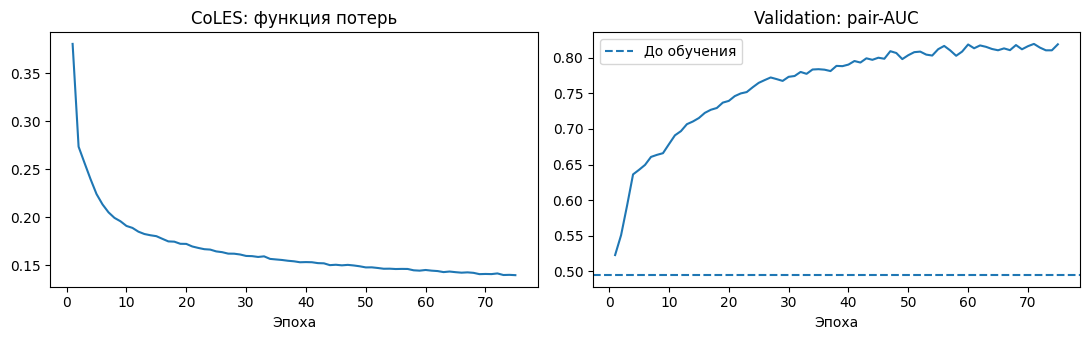

In [60]:
N_EPOCHS = 75
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
train_losses = []
val_pair_auc = []
best_pair_auc = -np.inf
best_weights = None

for epoch in range(1, N_EPOCHS + 1):
    model.train()
    epoch_losses = []

    for events, user_labels in train_loader:
        embeddings = model(*move_batch(events))
        loss, _ = coles_loss(embeddings, user_labels.to(DEVICE))

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        epoch_losses.append(loss.item())

    current_loss = float(np.mean(epoch_losses))
    current_auc = evaluate_pairs(model, val_probe)
    train_losses.append(current_loss)
    val_pair_auc.append(current_auc)

    if current_auc > best_pair_auc:
        best_pair_auc = current_auc
        best_weights = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    if epoch == 1 or epoch % 10 == 0 or epoch == N_EPOCHS:
        print(f"Эпоха {epoch:02d}: loss={current_loss:.4f}, val pair-AUC={current_auc:.3f}")

model.load_state_dict(best_weights)
print("Лучший pair-AUC на validation:", round(best_pair_auc, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].plot(range(1, N_EPOCHS + 1), train_losses)
axes[0].set(title="CoLES: функция потерь", xlabel="Эпоха")

axes[1].plot(range(1, N_EPOCHS + 1), val_pair_auc)
axes[1].axhline(pair_auc_before, ls="--", label="До обучения")
axes[1].set(title="Validation: pair-AUC", xlabel="Эпоха")
axes[1].legend()

plt.tight_layout()
plt.show()

### 6. Downstream: классификация пола

До этого момента CoLES обучался без меток `F/M`. Теперь подадим всю последовательность каждого пользователя в обученный энкодер и получим вектор из последнего скрытого состояния GRU.

Сравним три набора признаков с одним классификатором Logistic Regression:

1. `Genre profile` — доли жанров среди положительно оценённых фильмов и простые статистики оценок.
2. `CoLES` — эмбеддинг истории оценок.
3. `CoLES + genre` — объединение обоих наборов признаков.

Разбиение проводится по пользователям.

In [61]:
@torch.no_grad()
def encode_users(user_ids, encoder, batch_size=24):
    encoder.eval()
    vectors = []

    for start in range(0, len(user_ids), batch_size):
        current_users = user_ids[start:start + batch_size]
        events = [sequences[int(user_id)] for user_id in current_users]
        vectors.append(encoder(*move_batch(pad_events(events))).cpu().numpy())

    return np.concatenate(vectors, axis=0)


def genre_profile(user_id):
    movies, ratings = sequences[int(user_id)]
    genres = G[movies]
    liked = ratings >= 4

    genre_frequencies = genres[liked].mean(axis=0) if liked.any() else genres.mean(axis=0)
    summary = np.array([
        np.log1p(len(ratings)), ratings.mean(), ratings.std(), liked.mean()
    ], dtype=np.float32)

    return np.r_[genre_frequencies, summary].astype(np.float32)


X_train_coles = encode_users(train_users, model)
X_test_coles = encode_users(test_users, model)
X_train_genre = np.vstack([genre_profile(user_id) for user_id in train_users])
X_test_genre = np.vstack([genre_profile(user_id) for user_id in test_users])

y_train = gender_labels[train_users]
y_test = gender_labels[test_users]

assert np.isfinite(X_train_coles).all() and np.isfinite(X_test_coles).all()
print("Размерность CoLES-эмбеддингов:", X_train_coles.shape, X_test_coles.shape)

Размерность CoLES-эмбеддингов: (4228, 96) (906, 96)


In [63]:
def fit_and_predict(X_train, X_test):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    classifier = LogisticRegression(
        C=1.0, class_weight="balanced", max_iter=2000, random_state=42
    )
    classifier.fit(X_train_scaled, y_train)
    return classifier.predict_proba(X_test_scaled)[:, 1]


features = {
    "Genre profile": (X_train_genre, X_test_genre),
    "CoLES": (X_train_coles, X_test_coles),
    "CoLES + genre": (
        np.column_stack([X_train_coles, X_train_genre]),
        np.column_stack([X_test_coles, X_test_genre]),
    ),
}

results = []
for name, (X_train, X_test) in features.items():
    probabilities = fit_and_predict(X_train, X_test)
    predictions = probabilities >= 0.5

    results.append({
        "Модель": name,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "F1 (F)": f1_score(y_test, predictions, zero_division=0),
    })

print("Test: классификация на пользователях, не участвовавших в обучении CoLES")
display(pl.DataFrame(results).with_columns(pl.exclude("Модель").round(3)))

Test: классификация на пользователях, не участвовавших в обучении CoLES


Модель,ROC-AUC,Balanced accuracy,F1 (F)
str,f64,f64,f64
"""Genre profile""",0.807,0.71,0.581
"""CoLES""",0.825,0.752,0.631
"""CoLES + genre""",0.834,0.762,0.644


**Вопрос**

Что означает ситуация, когда `pair-AUC` растёт, а качество downstream-классификации остаётся прежним?